In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import Perceptron, LogisticRegression, SGDClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, PowerTransformer

# estudo árvores
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.metrics import ConfusionMatrixDisplay

from xgboost import XGBClassifier
from xgboost import plot_importance

from src.config import DADOS_LIMPOS
from src.graficos import plot_comparar_metricas_modelos
from src.models import RANDOM_STATE
from src.models import (
    grid_search_cv_classificador,
    treinar_e_validar_modelo_classificacao,
    organiza_resultados,
)

sns.set_theme(palette="bright")

In [3]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,...,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,...,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,...,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,...,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,...,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,...,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [4]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [5]:
le = LabelEncoder()

y = le.fit_transform(y)

y[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [6]:
seletor_mi = SelectKBest(mutual_info_classif, k=15)

X_mi = seletor_mi.fit_transform(X, y)

X_mi.shape

(569, 15)

In [7]:
seletor_mi.get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [8]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [9]:
preprocessamento = Pipeline(
    steps=[
        ("scaler", PowerTransformer()),
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

preprocessamento_arvore = Pipeline(
    steps=[
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

In [10]:
classificadores = {
    "DummyClassifier": {
        "preprocessor": None,
        "classificador": DummyClassifier(strategy="stratified")
    },
    "Perceptron": {
        "preprocessor": preprocessamento,
        "classificador": Perceptron()
    },
    "LogisticRegression": {
        "preprocessor": preprocessamento,
        "classificador": LogisticRegression()
    },
    "SGDClassifier": {
        "preprocessor": preprocessamento,
        "classificador": SGDClassifier()
    },
    
    # adicionar modelos baseados em árvores de decisão
    
    "DecisionTreeClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": DecisionTreeClassifier()
    },
    "RandomForestClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    },
    "XGBClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    },
}

In [11]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_classificacao(X, y, kf, **classificador)
    for nome_modelo, classificador in classificadores.items()
}

df_resultados = organiza_resultados(resultados)

df_resultados

,model,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
0,DummyClassifier,0.00101,0.00628,0.5,0.465608,0.329412,0.333333,0.325581,0.512119,0.3831,0.00729
1,DummyClassifier,0.00105,0.007377,0.54386,0.514576,0.395349,0.395349,0.395349,0.519161,0.38674,0.008427
2,DummyClassifier,0.000656,0.005796,0.552632,0.521825,0.4,0.395349,0.404762,0.554563,0.39868,0.006452
3,DummyClassifier,0.000799,0.00585,0.570175,0.545635,0.436782,0.422222,0.452381,0.458333,0.351675,0.006649
4,DummyClassifier,0.000523,0.004966,0.548673,0.524145,0.413793,0.4,0.428571,0.559859,0.404591,0.005489
5,Perceptron,0.065237,0.006427,0.938596,0.918605,0.911392,1.0,0.837209,0.987881,0.982831,0.071663
6,Perceptron,0.057875,0.006293,0.894737,0.865051,0.842105,0.969697,0.744186,0.985915,0.977328,0.064168
7,Perceptron,0.064489,0.00604,0.921053,0.922619,0.896552,0.866667,0.928571,0.982143,0.978283,0.070529
8,Perceptron,0.056815,0.005717,0.95614,0.960317,0.942529,0.911111,0.97619,0.995701,0.993515,0.062532
9,Perceptron,0.0624,0.006006,0.964602,0.952381,0.95,1.0,0.904762,0.996982,0.995172,0.068406


In [12]:
df_resultados.groupby("model").mean().sort_values("test_recall")

,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
model,,,,,,,,,,
DummyClassifier,0.000808,0.006054,0.543068,0.514358,0.395067,0.389251,0.401329,0.520807,0.384957,0.006861
DecisionTreeClassifier,0.04695,0.005961,0.906893,0.901022,0.874454,0.876294,0.87763,0.901022,0.813732,0.052911
Perceptron,0.061363,0.006096,0.935026,0.923795,0.908516,0.949495,0.878184,0.989724,0.985426,0.06746
SGDClassifier,0.07077,0.008223,0.94032,0.932586,0.917639,0.940486,0.90144,0.989197,0.984758,0.078992
RandomForestClassifier,0.207421,0.048853,0.942028,0.934762,0.919985,0.939632,0.905869,0.98843,0.983118,0.256274
XGBClassifier,0.167507,0.011951,0.938519,0.932751,0.916798,0.924712,0.910299,0.985474,0.980406,0.179458
LogisticRegression,0.069413,0.008112,0.952585,0.947818,0.935613,0.944606,0.929125,0.992078,0.989293,0.077525


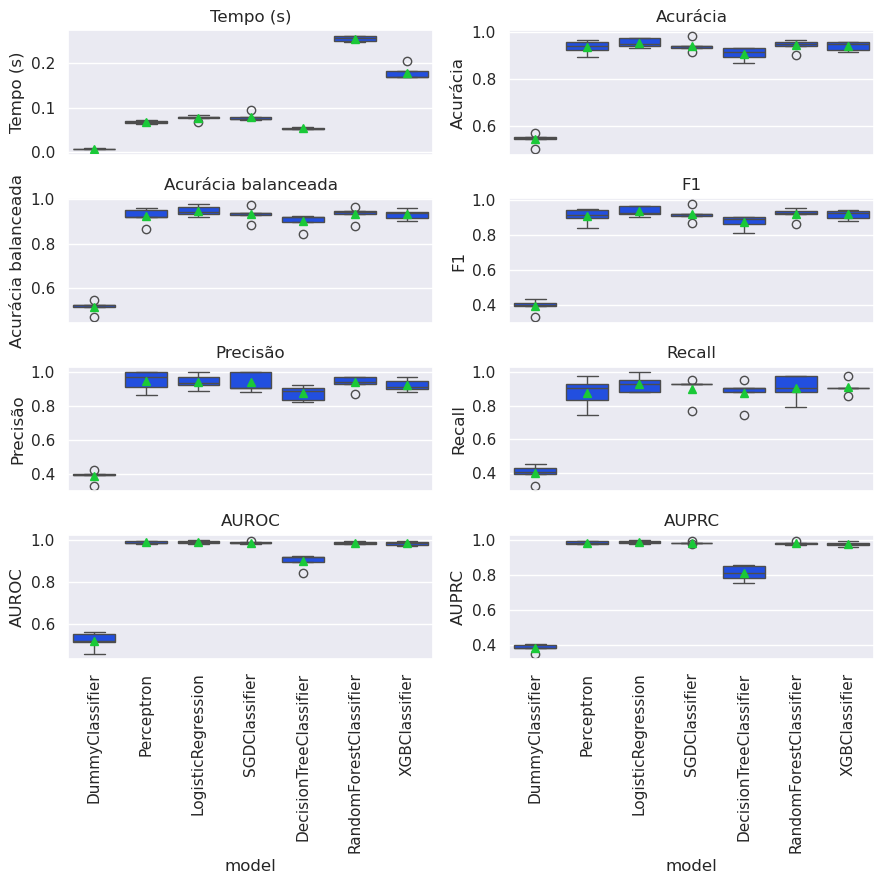

In [13]:
plot_comparar_metricas_modelos(df_resultados)

Principais hiperparâmetros do **XGBoostClassifier**:

- **`max_depth`**: Profundidade máxima da árvore. Controla a complexidade do modelo.
- **`min_child_weight`**: Peso mínimo necessário para dividir um nó. Influencia o tamanho mínimo das folhas.
- **`gamma`**: Redução mínima de perda para realizar uma divisão. Quanto maior o valor, mais conservadora é a árvore.
- **`subsample`**: Proporção de dados amostrados para cada árvore, útil para reduzir overfitting.
- **`colsample_bytree`**: Proporção de features amostradas para construir cada árvore.

- **`learning_rate` (ou `eta`)**: Taxa de aprendizado. Reduz o impacto de cada árvore, suavizando o processo.
- **`n_estimators`**: Número de árvores ou rodadas de boosting.
- **`lambda`**: Regularização L2 para os pesos. Aumenta a robustez contra overfitting.
- **`alpha`**: Regularização L1 para pesos, útil para regularização de árvores mais esparsas.
- **`scale_pos_weight`**: Controla o balanceamento de classes quando há classes desbalanceadas.


Valores padrão dos hiperparâmetros do **XGBoostClassifier** podem ser encontrados na documentação oficial:

https://xgboost.readthedocs.io/en/latest/parameter.html

In [14]:
np.bincount(y)

array([357, 212])

In [15]:
scale_pos_weight = np.bincount(y)[0] / np.bincount(y)[1]
scale_pos_weight

1.6839622641509433

In [19]:
# param grid para o modelo em estudo
param_grid = {
    "clf__max_depth": [3, 6, 10],  # Profundidade da árvore
    #"clf__min_child_weight": [1, 3, 5],  # Peso mínimo de uma folha
    #"clf__gamma": [0, 0.1, 0.3],  # Redução mínima de perda para uma divisão
    "clf__subsample": [0.6, 0.8, 1.0],  # Proporção de amostras usadas para cada árvore
    "clf__colsample_bytree": [0.6, 0.8, 1.0],  # Proporção de features para cada árvore
    "clf__learning_rate": [0.1, 0.3, 0.5],  # Taxa de aprendizado
    "clf__n_estimators": [10, 50, 100],  # Número de árvores
    "clf__reg_lambda": [1, 2, 5],  # Regularização L2
    "clf__reg_alpha": [0, 0.5, 1],  # Regularização L1
    "clf__scale_pos_weight": [1, scale_pos_weight],  # Peso das classes
}


In [20]:
# classificador baseado em árvore de decisão
clf = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1)

grid_search = grid_search_cv_classificador(
    clf, param_grid, kf, preprocessamento_arvore, refit_metric="recall"
)

grid_search

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('selector',
                                                         SelectKBest(k=15,
                                                                     score_func=<function mutual_info_classif at 0x7eddffddd120>))])),
                                       ('clf',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=N...
             param_grid={'clf__colsample_bytree': [0.6, 0.8, 1.0],
                         'clf__learning_rate': [0.1, 0.3, 0.5],
                         'clf__max_depth': [3, 6, 10],
                         'clf__n_estimators': [10, 50, 100],
                         'clf__reg_alpha': [0, 0.5, 1],
                         'clf__reg_lambda': [1, 2, 5],
                         'clf__scale_pos_weight': [1, 1.6839622641509433],
                         'clf__subsample': [0.6, 0.8, 1.0]},
             refit='recall',
             scoring=['accuracy', 'balanced_accuracy', 'f1', 'precision',
                      'recall', 'roc_auc', 'average_precision'],
             verbose=1)

In [21]:
grid_search.fit(X, y)

Fitting 5 folds for each of 4374 candidates, totalling 21870 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('selector',
                                                         SelectKBest(k=15,
                                                                     score_func=<function mutual_info_classif at 0x7eddffddd120>))])),
                                       ('clf',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=N...
             param_grid={'clf__colsample_bytree': [0.6, 0.8, 1.0],
                         'clf__learning_rate': [0.1, 0.3, 0.5],
                         'clf__max_depth': [3, 6, 10],
                         'clf__n_estimators': [10, 50, 100],
                         'clf__reg_alpha': [0, 0.5, 1],
                         'clf__reg_lambda': [1, 2, 5],
                         'clf__scale_pos_weight': [1, 1.6839622641509433],
                         'clf__subsample': [0.6, 0.8, 1.0]},
             refit='recall',
             scoring=['accuracy', 'balanced_accuracy', 'f1', 'precision',
                      'recall', 'roc_auc', 'average_precision'],
             verbose=1)

In [22]:
grid_search.best_params_

{'clf__colsample_bytree': 0.8,
 'clf__learning_rate': 0.3,
 'clf__max_depth': 3,
 'clf__n_estimators': 10,
 'clf__reg_alpha': 0.5,
 'clf__reg_lambda': 5,
 'clf__scale_pos_weight': 1.6839622641509433,
 'clf__subsample': 0.6}

In [23]:
grid_search.best_score_

0.9573643410852715

In [24]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('selector',
                                  SelectKBest(k=15,
                                              score_func=<function mutual_info_classif at 0x7eddffddd120>))])),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.8, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric=None,
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.3,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=10, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [25]:
grid_search.best_estimator_["preprocessor"].get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [26]:
grid_search.best_estimator_["clf"].get_booster().get_score(importance_type="weight")

{'f0': 1.0,
 'f1': 7.0,
 'f2': 8.0,
 'f3': 2.0,
 'f4': 2.0,
 'f5': 4.0,
 'f6': 10.0,
 'f7': 3.0,
 'f8': 6.0,
 'f10': 3.0,
 'f11': 2.0,
 'f14': 5.0}

In [31]:
sorted(
    grid_search.best_estimator_["clf"].get_booster().get_score(importance_type="weight").items(),
    key=lambda x: x[1],
)

[('f0', 1.0),
 ('f3', 2.0),
 ('f4', 2.0),
 ('f11', 2.0),
 ('f7', 3.0),
 ('f10', 3.0),
 ('f5', 4.0),
 ('f14', 5.0),
 ('f8', 6.0),
 ('f1', 7.0),
 ('f2', 8.0),
 ('f6', 10.0)]

In [32]:
indices_ordenados_weight = [
    int(item[0].replace("f", ""))
    for item in sorted(
        grid_search.best_estimator_["clf"].get_booster().get_score(importance_type="weight").items(),
        key=lambda x: x[1],
    )
]

indices_ordenados_weight

[0, 3, 4, 11, 7, 10, 5, 14, 8, 1, 2, 6]

In [29]:
grid_search.best_estimator_["preprocessor"].get_feature_names_out()[indices_ordenados_weight]

array(['area_mean', 'compactness_mean', 'compactness_worst',
       'perimeter_worst', 'concavity_mean', 'perimeter_se',
       'concave points_mean', 'radius_worst', 'concavity_worst',
       'area_se', 'area_worst', 'concave points_worst'], dtype=object)

ValueError: The number of FixedLocator locations (15), usually from a call to set_ticks, does not match the number of labels (12).

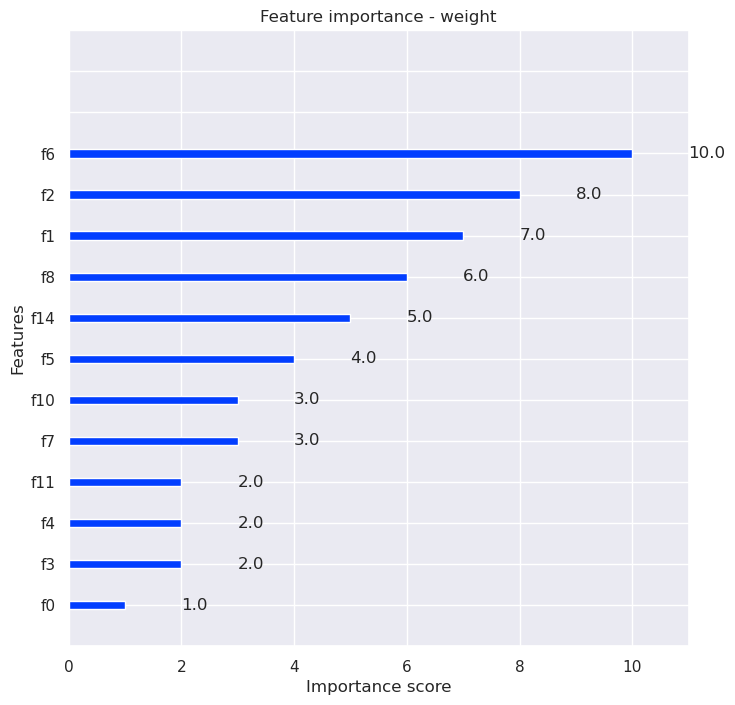

In [30]:
fig, ax = plt.subplots(figsize=(8, 8))

plot_importance(
    grid_search.best_estimator_["clf"],
    ax=ax,
    importance_type="weight",
    title="Feature importance - weight"
)

plt.yticks(
    np.arange(len(grid_search.best_estimator_["preprocessor"].get_feature_names_out())),
    grid_search.best_estimator_["preprocessor"].get_feature_names_out()[indices_ordenados_weight]
)

plt.show()

In [36]:
grid_search.best_estimator_["clf"].get_booster().get_score(importance_type="gain")

{'f0': 2.9416544437408447,
 'f1': 4.544686317443848,
 'f2': 62.57622528076172,
 'f3': 2.132439374923706,
 'f4': 1.4343340396881104,
 'f5': 39.69291305541992,
 'f6': 13.5285005569458,
 'f7': 1.5623430013656616,
 'f8': 8.056190490722656,
 'f9': 1.3047127723693848,
 'f10': 1.6248184442520142,
 'f11': 28.884212493896484,
 'f12': 2.57850980758667,
 'f13': 2.4949328899383545,
 'f14': 9.62252140045166}

In [37]:
indices_ordenados_gain = [
    int(item[0].replace("f", ""))
    for item in sorted(
        grid_search.best_estimator_["clf"].get_booster().get_score(importance_type="gain").items(),
        key=lambda x: x[1],
    )
]

indices_ordenados_gain

[9, 4, 7, 10, 3, 13, 12, 0, 1, 8, 14, 6, 11, 5, 2]

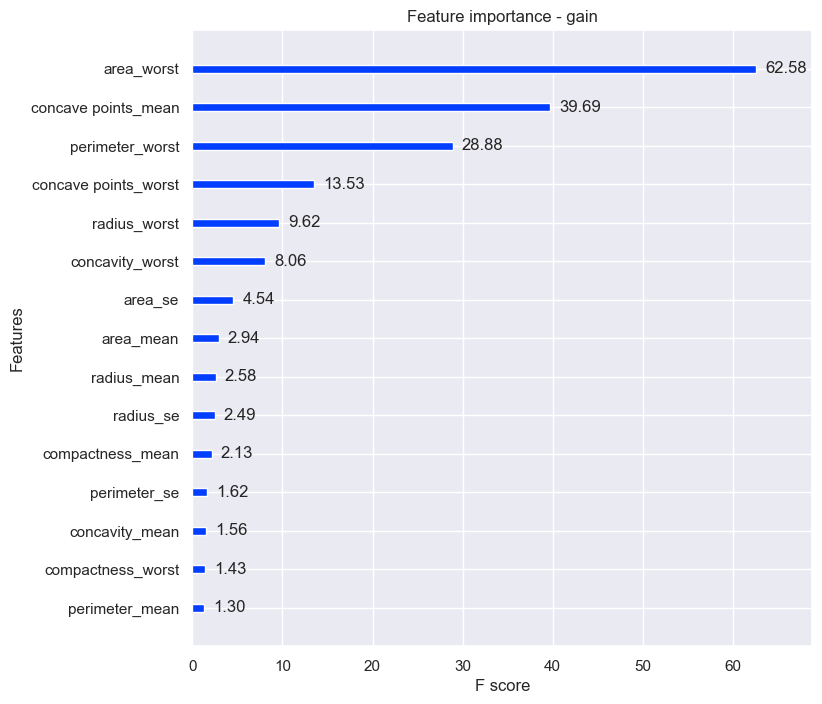

In [39]:
fig, ax = plt.subplots(figsize=(8, 8))

plot_importance(
    grid_search.best_estimator_["clf"],
    ax=ax,
    importance_type="gain",
    title="Feature importance - gain",
    values_format="{v:.2f}"
)

plt.yticks(
    np.arange(len(grid_search.best_estimator_["preprocessor"].get_feature_names_out())),
    grid_search.best_estimator_["preprocessor"].get_feature_names_out()[indices_ordenados_gain],
)

plt.show()

In [40]:
perm_imp = permutation_importance(
    grid_search.best_estimator_,
    X,
    y,
    n_repeats=10,
    random_state=RANDOM_STATE
)

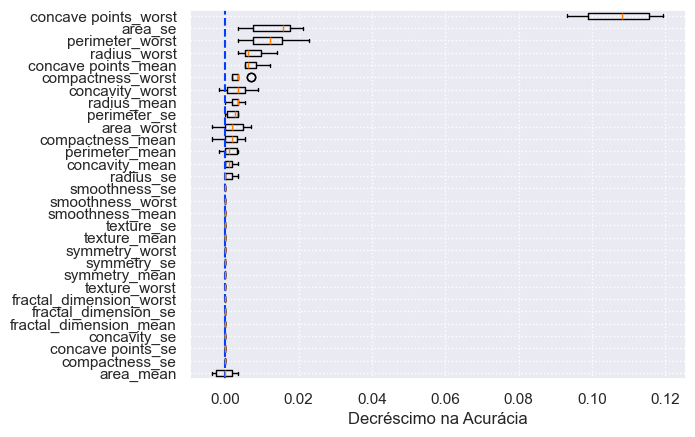

In [41]:
fig, ax = plt.subplots()

ordem = perm_imp.importances_mean.argsort()

ax.boxplot(perm_imp.importances[ordem].T, vert=False, tick_labels=X.columns[ordem])
ax.axvline(x=0, linestyle="--")
ax.set_xlabel("Decréscimo na Acurácia")
ax.grid(True, linestyle=":")

plt.show()

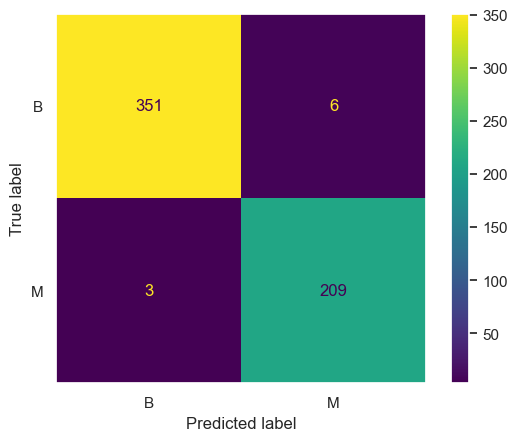

In [42]:
ConfusionMatrixDisplay.from_estimator(
    grid_search.best_estimator_,
    X,
    y,
    display_labels=le.classes_,
)
plt.grid(False)
plt.show()

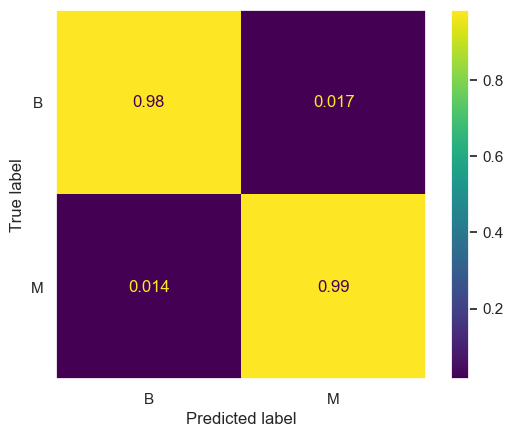

In [43]:
ConfusionMatrixDisplay.from_estimator(
    grid_search.best_estimator_,
    X,
    y,
    display_labels=le.classes_,
    normalize="true",
)
plt.grid(False)
plt.show()